# Reconhecimento de Fonemas e Palavras via Rede Neural RBF
**Universidade Federal do Maranhão (UFMA)**  
**Centro de Ciências Exatas e Tecnologia (CCET)**  
**Programa de Pós-Graduação em Ciência da Computação (PPGCC / DCCMAPI)**  
**Disciplina:** Redes Neurais Artificiais  
**Professor:** Prof. Dr. Areolino de Almeida Neto  
**Aluno:** Ricardo Diniz Mendes  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RicDM/trabalhos_redes_neurais/blob/main/RBF/reconhecimento_fonemas_rbf.ipynb)

---

### Visão Geral do Notebook
Este notebook implementa um sistema de classificação acústica para reconhecimento de 6 classes fonéticas das palavras **DIREITA** (`DI`, `REI`, `TA`) e **ESQUERDA** (`ES`, `QUER`, `DA`) através de uma **Rede Neural de Funções de Base Radial (RBF)** desenvolvida em **Python/NumPy puro** (*from scratch*).

O notebook prioriza a clareza prática e a modularidade:
- **Separação por Incrementos:** Cada bloco fundamental da rede (centros via WTA, aberturas gaussianas $\sigma$, matriz de ativação $\Phi$, solvers linear Ridge/LMS e inferência) é construído e testado em sua própria célula isolada.
- **Documentação Funcional:** Cada função contém explicações objetivas sobre seu objetivo, entradas esperadas e saídas geradas.
- **Aprofundamento Teórico:** As deduções analíticas completas, formalizações matemáticas e referências bibliográficas encontram-se detalhadas no relatório formal em PDF do trabalho.


## 1. Configuração do Ambiente e Inicialização
Nesta célula, importamos as bibliotecas matemáticas (`numpy`), de áudio (`soundfile`) e visualização (`matplotlib`), fixamos a semente pseudoaleatória mestre para garantir total reprodutibilidade e definimos uma função utilitária para exibição de tabelas comparativas formatadas.


In [1]:
import os
import sys
import glob
import time
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display, Markdown

# Fixação da semente para reprodutibilidade
SEED_MESTRE = 42
np.random.seed(SEED_MESTRE)

# Configuração visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Suporte automático ao Google Colab
if 'google.colab' in sys.modules:
    if not os.path.exists('dados/dataset'):
        print("[!] Executando no Google Colab. Clonando repositório oficial...")
        !git clone https://github.com/RicDM/trabalhos_redes_neurais.git /tmp/repo_rbf
        !cp -r /tmp/repo_rbf/dados ./dados
        print("[OK] Dados configurados com sucesso no Colab.")

CLASSES = ["DI", "REI", "TA", "ES", "QUER", "DA"]
LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}
DATASET_PATH = "dados/dataset"

def exibir_tabela_comparativa(headers, rows, titulo=""):
    """Exibe dados em formato de tabela Markdown interativa e texto plano."""
    lines = []
    if titulo:
        lines.append(f"#### {titulo}\n")
    lines.append("| " + " | ".join(headers) + " |")
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for r in rows:
        lines.append("| " + " | ".join(str(c) for c in r) + " |")
    display(Markdown("\n".join(lines)))
    
    col_w = [max(len(str(headers[i])), max(len(str(r[i])) for r in rows)) for i in range(len(headers))]
    sep = "+-" + "-+-".join("-" * w for w in col_w) + "-+"
    hdr = "| " + " | ".join(f"{str(headers[i]):<{col_w[i]}}" for i in range(len(headers))) + " |"
    if titulo:
        print(f"\n=== {titulo} ===")
    print(sep)
    print(hdr)
    print(sep)
    for r in rows:
        print("| " + " | ".join(f"{str(r[i]):<{col_w[i]}}" for i in range(len(headers))) + " |")
    print(sep)

print(f"[OK] Ambiente pronto. Total de classes alvo: {len(CLASSES)} -> {CLASSES}")


[OK] Ambiente pronto. Total de classes alvo: 6 -> ['DI', 'REI', 'TA', 'ES', 'QUER', 'DA']


## 2. Incremento: Extração de Características Espectrais (FFT)
**O que esta função faz:**  
Calcula o espectro de magnitude unilateral do sinal acústico via Transformada Rápida de Fourier (FFT unilateral com `np.fft.rfft`) e agrupa as frequências em $B=48$ bandas espectrais uniformes, calculando a energia média em cada banda.

- **Entrada:**
  - `x`: Vetor unidimensional com as amostras temporais do áudio.
  - `n_bandas`: Quantidade de bandas espectrais desejadas (padrão: 48).
- **Saída:**
  - Vetor NumPy 1D de tamanho `n_bandas` contendo as energias médias por banda.


Dimensão do vetor de características extraído: (48,) (valores no intervalo [0.0111, 18.5329])


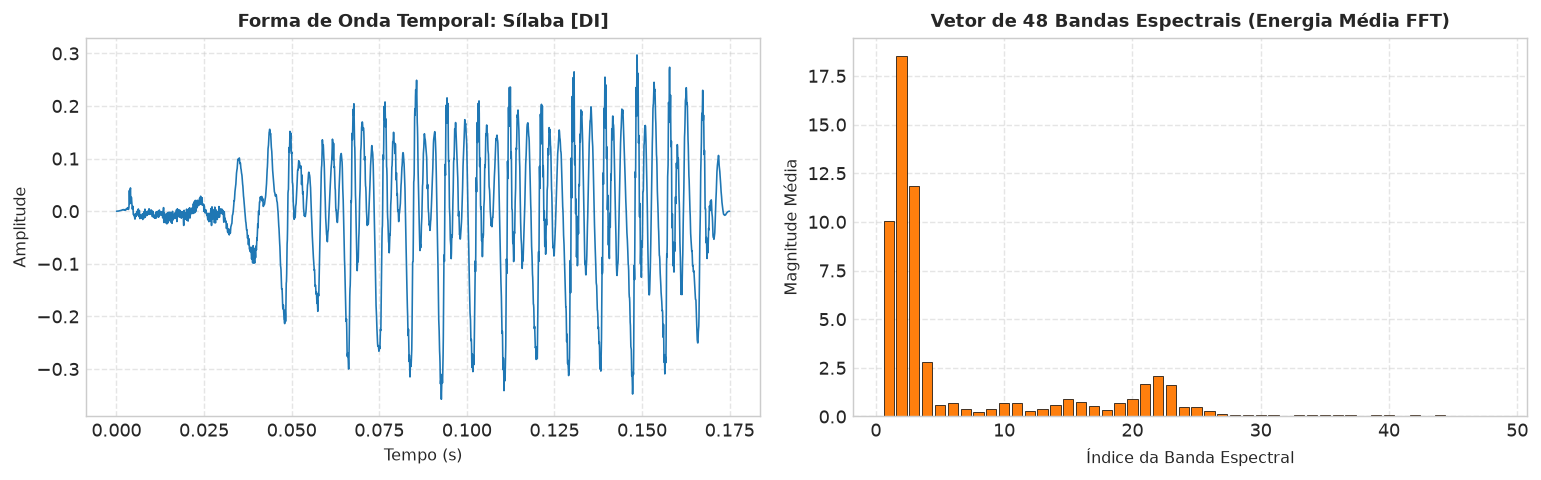

In [2]:
def extrair_features_fft(x, n_bandas=48):
    """Extrai vetor de características agrupando a FFT unilateral em n_bandas uniformes."""
    fft_vals = np.abs(np.fft.rfft(x))
    bins = np.array_split(fft_vals, n_bandas)
    return np.array([np.mean(b) if len(b) > 0 else 0.0 for b in bins], dtype=np.float32)

# Teste e inspeção visual: carrega uma amostra de 'DI' e exibe forma de onda e bandas FFT
amostra_exemplo = sorted(glob.glob(f"{DATASET_PATH}/DI/*.wav"))[0]
audio_ex, sr_ex = sf.read(amostra_exemplo)
feat_ex = extrair_features_fft(audio_ex, n_bandas=48)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
t_ex = np.linspace(0, len(audio_ex)/sr_ex, len(audio_ex))
axes[0].plot(t_ex, audio_ex, color='#1f77b4', lw=0.9)
axes[0].set_title("Forma de Onda Temporal: Sílaba [DI]", fontsize=10, fontweight='bold')
axes[0].set_xlabel("Tempo (s)", fontsize=9)
axes[0].set_ylabel("Amplitude", fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].bar(range(1, 49), feat_ex, color='#ff7f0e', edgecolor='black', linewidth=0.4)
axes[1].set_title("Vetor de 48 Bandas Espectrais (Energia Média FFT)", fontsize=10, fontweight='bold')
axes[1].set_xlabel("Índice da Banda Espectral", fontsize=9)
axes[1].set_ylabel("Magnitude Média", fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Dimensão do vetor de características extraído: {feat_ex.shape} (valores no intervalo [{feat_ex.min():.4f}, {feat_ex.max():.4f}])")


## 3. Incremento: Carregamento do Dataset, Normalização Min-Max e Particionamento
**O que este passo faz:**  
1. Carrega todos os 423 arquivos de áudio do corpus fonético e extrai o vetor de 48 bandas de cada um.
2. Aplica a **Normalização Min-Max $[0, 1]$** em cada atributo (Slide 9 das lâminas de RBF), garantindo que as distâncias euclidianas na função de base radial gaussiana não fiquem distorcidas por bandas de maior amplitude absoluta.
3. Particiona o conjunto de forma estratificada:
   - **75% Treinamento (316 amostras):** Usado para ajustar os centros radiais e otimizar os pesos de saída.
   - **15% Validação (64 amostras):** Usado para comparar e escolher hiperparâmetros ($K$, $\sigma$, solver).
   - **10% Teste Cego (43 amostras):** Isolado estritamente para avaliação final.


In [3]:
def carregar_dataset_completo(n_bandas=48):
    """Carrega todas as amostras das 6 classes fonéticas e seus caminhos de arquivo."""
    X, y, caminhos = [], [], []
    for c in CLASSES:
        for f in sorted(glob.glob(f"{DATASET_PATH}/{c}/*.wav")):
            audio, sr = sf.read(f)
            X.append(extrair_features_fft(audio, n_bandas=n_bandas))
            y.append(LABEL_MAP[c])
            caminhos.append(f)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64), caminhos

X_raw, y, caminhos = carregar_dataset_completo(48)

# Normalização Min-Max [0, 1] conforme Slide 9 da Aula 06
X_min = X_raw.min(axis=0)
X_max = X_raw.max(axis=0)
X = (X_raw - X_min) / (X_max - X_min + 1e-8)

# Particionamento Estratificado (75% Treino, 15% Validação, 10% Teste Cego)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.10, random_state=SEED_MESTRE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15/0.90, random_state=SEED_MESTRE, stratify=y_temp
)

print(f"Total de Amostras: {len(y)} (48 atributos espectrais normalizados em [0, 1])")
print(f"  -> Treino:    {len(y_train)} amostras (74.7%)")
print(f"  -> Validação: {len(y_val)} amostras (15.1%)")
print(f"  -> Teste:     {len(y_test)} amostras (10.2%)")


Total de Amostras: 423 (48 atributos espectrais normalizados em [0, 1])
  -> Treino:    316 amostras (74.7%)
  -> Validação: 64 amostras (15.1%)
  -> Teste:     43 amostras (10.2%)


## 4. Incremento: Inicialização e Ajuste dos Centros via Winner-Take-All (WTA)
**O que estas funções fazem:**  
- `inicializar_centros_estratificados`: Seleciona centros iniciais balanceados entre as classes de treinamento para assegurar que todas as regiões fonéticas possuam representantes radiais, evitando neurônios ociosos.
- `ajustar_centros_wta`: Executa o algoritmo competitivo não supervisionado *Winner-Take-All* (Slides 10–11 da Aula 06). A cada amostra $x$, localiza o centro vencedor $c_{win} = \arg\min_j \|x - c_j\|$ e aproxima esse centro da amostra com decaimento da taxa de aprendizado. Monitora o **Erro de Quantização** $E_q = \frac{1}{N} \sum_{i=1}^N \min_j \|x_i - c_j\|^2$.

- **Entradas:**
  - `X`: Dados de treinamento normalizados $(N \times D)$.
  - `y`: Rótulos de classe para inicialização estratificada.
  - `n_centros`: Quantidade $K$ de neurônios radiais.
  - `epocas`, `lr`: Número de iterações e taxa de aprendizado inicial do WTA.
- **Saídas:**
  - `centros`: Matriz $(K \times D)$ com os centros ajustados.
  - `eq_history`: Lista com a evolução do erro de quantização $E_q$ por época.


In [4]:
def inicializar_centros_estratificados(X, y, n_centros, seed=42):
    """Inicializa centros distribuídos uniformemente entre as classes do treino."""
    rng = np.random.RandomState(seed)
    n_samples = X.shape[0]
    n_classes = len(np.unique(y)) if y is not None else 1
    
    if y is not None:
        centros_init = []
        per_class = max(1, n_centros // n_classes)
        for c_idx in range(n_classes):
            idx_c = np.where(y == c_idx)[0]
            if len(idx_c) > 0:
                chosen = rng.choice(idx_c, min(per_class, len(idx_c)), replace=False)
                centros_init.append(X[chosen])
        centros_cat = np.vstack(centros_init)
        if len(centros_cat) < n_centros:
            rem = n_centros - len(centros_cat)
            centros_cat = np.vstack([centros_cat, X[rng.choice(n_samples, rem, replace=False)]])
        return centros_cat[:n_centros].copy()
    else:
        return X[rng.choice(n_samples, n_centros, replace=False)].copy()

def ajustar_centros_wta(X, centros_iniciais, epocas=100, lr=0.1, seed=42):
    """Ajusta os centros radiais via algoritmo competitivo WTA e calcula o erro de quantização."""
    rng = np.random.RandomState(seed)
    centros = centros_iniciais.copy()
    n_samples = X.shape[0]
    eq_history = []
    
    for ep in range(epocas):
        eta = lr * (1.0 - ep / epocas) + 0.001
        perm = rng.permutation(n_samples)
        for idx in perm:
            x = X[idx]
            dists = np.linalg.norm(centros - x, axis=1)
            win_idx = np.argmin(dists)
            centros[win_idx] += eta * (x - centros[win_idx])
            
        # Cálculo do Erro de Quantização Eq (Slide 11)
        all_dists = np.linalg.norm(X[:, np.newaxis, :] - centros[np.newaxis, :, :], axis=2)
        min_dists_sq = np.min(all_dists, axis=1) ** 2
        eq_history.append(float(np.mean(min_dists_sq)))
        
    return centros, eq_history


### Demonstração Isolada: Treinamento dos Centros via WTA
Executamos o ajuste dos centros para $K=48$ e visualizamos a redução do erro de quantização $E_q$ e a distribuição dos centros sobre as amostras nas duas primeiras bandas espectrais.


Erro de Quantização Inicial: 0.18922
Erro de Quantização Final:   0.15193 (Redução de 19.7%)


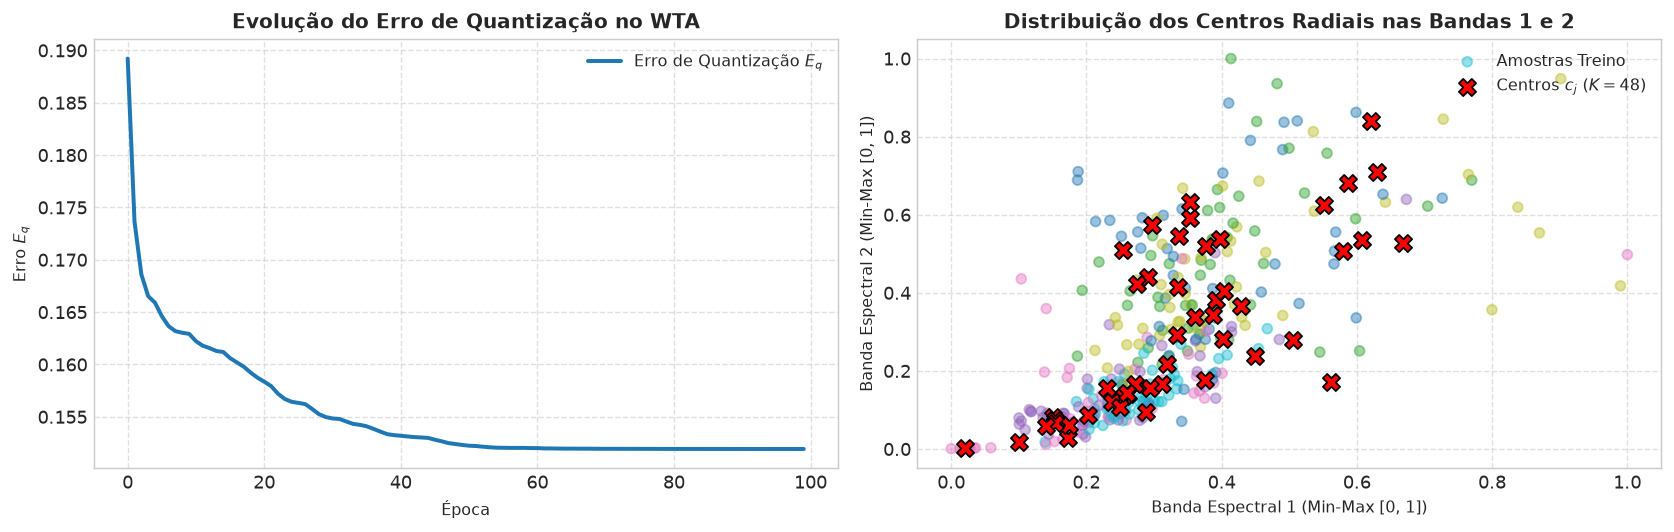

In [5]:
centros_iniciais_demo = inicializar_centros_estratificados(X_train, y_train, n_centros=48, seed=SEED_MESTRE)
centros_demo, eq_hist_demo = ajustar_centros_wta(X_train, centros_iniciais_demo, epocas=100, lr=0.1, seed=SEED_MESTRE)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# 1. Curva do Erro Eq
axes[0].plot(eq_hist_demo, color='#1f77b4', lw=2.2, label='Erro de Quantização $E_q$')
axes[0].set_title('Evolução do Erro de Quantização no WTA', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Época', fontsize=9)
axes[0].set_ylabel('Erro $E_q$', fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=9)

# 2. Centros ajustados sobre as amostras
scatter = axes[1].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='tab10', alpha=0.45, s=30, label='Amostras Treino')
axes[1].scatter(centros_demo[:, 0], centros_demo[:, 1], c='red', marker='X', s=90, edgecolors='black', label='Centros $c_j$ ($K=48$)')
axes[1].set_title('Distribuição dos Centros Radiais nas Bandas 1 e 2', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Banda Espectral 1 (Min-Max [0, 1])', fontsize=9)
axes[1].set_ylabel('Banda Espectral 2 (Min-Max [0, 1])', fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=9, loc='upper right')

plt.tight_layout()
plt.show()

print(f"Erro de Quantização Inicial: {eq_hist_demo[0]:.5f}")
print(f"Erro de Quantização Final:   {eq_hist_demo[-1]:.5f} (Redução de {((eq_hist_demo[0]-eq_hist_demo[-1])/eq_hist_demo[0])*100:.1f}%)")


## 5. Incremento: Cálculo das Aberturas Radiais ($\sigma$)
**O que esta função faz:**  
Calcula a largura de dispersão gaussiana $\sigma_j$ para cada um dos $K$ neurônios radiais a partir da matriz de distâncias mútuas entre os centros, implementando os métodos descritos no Slide 12 da Aula 06:
1. `raio_unico`: Raio global $\sigma = (d_{\max} / \sqrt{2K}) \cdot \alpha$;
2. `metade_minimo`: Raio local $\sigma_j = (d_{\min}(c_j) / 2) \cdot \alpha$;
3. `knn_mean`: Média dos $T$ centros mais próximos $\sigma_j = \left(\frac{1}{T} \sum_{t=1}^T d_t\right) \cdot \alpha$.

- **Entradas:**
  - `centros`: Matriz $(K \times D)$ com as posições dos centros radiais.
  - `metodo`: Nome do método (`"raio_unico"`, `"metade_minimo"`, `"knn_mean"`).
  - `k_vizinhos`: Número de vizinhos mais próximos $T$ (para `knn_mean`).
  - `escala`: Fator multiplicativo de ajuste $\alpha$.
- **Saída:**
  - Vetor NumPy 1D com os $K$ valores de abertura $\sigma_j$.


In [6]:
def calcular_sigmas(centros, metodo="knn_mean", k_vizinhos=2, escala=1.5):
    """Calcula as larguras de dispersão gaussiana sigma para cada centro radial."""
    K = centros.shape[0]
    dist_centros = np.zeros((K, K))
    for i in range(K):
        for j in range(K):
            dist_centros[i, j] = np.linalg.norm(centros[i] - centros[j]) if i != j else np.inf
                
    sigmas = np.zeros(K, dtype=np.float32)
    if metodo == "raio_unico":
        finite_dists = np.where(dist_centros == np.inf, 0, dist_centros)
        d_max = np.max(finite_dists)
        sig_val = (d_max / np.sqrt(2.0 * K)) * escala
        sigmas[:] = max(sig_val, 1e-4)
        
    elif metodo == "metade_minimo":
        for i in range(K):
            d_min = np.min(dist_centros[i])
            sigmas[i] = max((d_min / 2.0) * escala, 1e-4)
            
    elif metodo == "knn_mean":
        T = min(k_vizinhos, K - 1)
        for i in range(K):
            dists_sorted = np.sort(dist_centros[i])[:T]
            sigmas[i] = max(np.mean(dists_sorted) * escala, 1e-4)
            
    return sigmas

# Teste isolado: calcula sigmas para os centros demo
sigmas_demo = calcular_sigmas(centros_demo, metodo="knn_mean", k_vizinhos=2, escala=1.5)
print(f"Resumo dos Sigmas calculados (K={len(sigmas_demo)}, metodo='knn_mean', escala=1.5):")
print(f"  -> Sigma Mínimo: {sigmas_demo.min():.4f}")
print(f"  -> Sigma Médio:  {sigmas_demo.mean():.4f}")
print(f"  -> Sigma Máximo: {sigmas_demo.max():.4f}")


Resumo dos Sigmas calculados (K=48, metodo='knn_mean', escala=1.5):
  -> Sigma Mínimo: 0.1389
  -> Sigma Médio:  0.7439
  -> Sigma Máximo: 1.9144


## 6. Incremento: Mapeamento Não Linear e Matriz de Ativação ($\Phi$)
**O que esta função faz:**  
Mapeia os padrões de entrada $X \in \mathbb{R}^{N \times D}$ para o espaço de alta dimensionalidade gerado pelas funções de base radial gaussianas:
$$\phi_j(x) = \exp\left( - \frac{\|x - c_j\|^2}{2\sigma_j^2} \right)$$
O resultado é a matriz de ativação oculta $\Phi \in \mathbb{R}^{N \times K}$, onde cada coluna $j$ representa a resposta do $j$-ésimo neurônio radial.

- **Entradas:**
  - `X`: Matriz de padrões $(N \times D)$.
  - `centros`: Posições dos centros radiais $(K \times D)$.
  - `sigmas`: Vetor de larguras de dispersão $(K)$.
- **Saída:**
  - Matriz NumPy $\Phi$ de dimensões $(N \times K)$ com as ativações gaussianas normalizadas no intervalo $(0, 1]$.


In [7]:
def calcular_matriz_ativacao(X, centros, sigmas):
    """Calcula a matriz Phi de ativações gaussianas para todas as amostras em X."""
    N = X.shape[0]
    K = centros.shape[0]
    Phi = np.zeros((N, K), dtype=np.float32)
    for j in range(K):
        diff = X - centros[j]
        dist_sq = np.sum(diff ** 2, axis=1)
        Phi[:, j] = np.exp(-dist_sq / (2.0 * (sigmas[j] ** 2) + 1e-8))
    return Phi

# Teste isolado: gera Phi para os conjuntos de treino e validação
Phi_train_demo = calcular_matriz_ativacao(X_train, centros_demo, sigmas_demo)
Phi_val_demo = calcular_matriz_ativacao(X_val, centros_demo, sigmas_demo)

print(f"Dimensões da Matriz de Ativação Treino: {Phi_train_demo.shape} (N={Phi_train_demo.shape[0]}, K={Phi_train_demo.shape[1]})")
print(f"Ativação Média Global em Phi: {Phi_train_demo.mean():.4f} (Mín: {Phi_train_demo.min():.4f}, Máx: {Phi_train_demo.max():.4f})")


Dimensões da Matriz de Ativação Treino: (316, 48) (N=316, K=48)
Ativação Média Global em Phi: 0.3519 (Mín: 0.0000, Máx: 1.0000)


## 7. Incremento: Camada de Saída Linear via Pseudo-Inversa (Ridge / Tikhonov)
**O que esta função faz:**  
Resolve de forma analítica e exata os pesos da camada linear de saída através do método de Mínimos Quadrados Regularizados (Ridge / Tikhonov, Slide 13 da Aula 06):
$$W^* = (\Phi_{\text{bias}}^T \Phi_{\text{bias}} + \lambda I)^{-1} \Phi_{\text{bias}}^T D$$
onde $\Phi_{\text{bias}} = [\Phi \mid \mathbf{1}]$ inclui o termo de polarização (*bias*), $D$ é a matriz de rótulos *one-hot* das 6 classes e $\lambda$ previne singularidade numérica.

- **Entradas:**
  - `Phi`: Matriz de ativação da camada oculta $(N \times K)$.
  - `y`: Vetor de rótulos inteiros de classe $(N)$.
  - `n_classes`: Número de saídas (6 classes).
  - `l2_reg`: Fator de regularização $\lambda$ (padrão: $10^{-2}$).
- **Saídas:**
  - `W`: Matriz de pesos lineares $(K \times \text{n\_classes})$.
  - `bias`: Vetor de termos de polarização $(1 \times \text{n\_classes})$.


In [8]:
def ajustar_saida_pseudoinversa(Phi, y, n_classes=6, l2_reg=1e-2):
    """Calcula analiticamente os pesos de saída W e bias via Mínimos Quadrados Regularizados."""
    N = Phi.shape[0]
    Phi_bias = np.hstack([Phi, np.ones((N, 1), dtype=np.float32)])
    D = np.eye(n_classes)[y]
    
    reg_matrix = l2_reg * np.eye(Phi_bias.shape[1], dtype=np.float32)
    reg_matrix[-1, -1] = 0.0  # Não penaliza o termo de bias
    
    W_full = np.linalg.solve(Phi_bias.T @ Phi_bias + reg_matrix, Phi_bias.T @ D)
    W = W_full[:-1, :]
    bias = W_full[-1:, :]
    return W, bias

# Teste isolado: calcula W e bias analiticamente
W_ridge_demo, b_ridge_demo = ajustar_saida_pseudoinversa(Phi_train_demo, y_train, n_classes=6, l2_reg=1e-2)
print(f"Pesos lineares ajustados: W={W_ridge_demo.shape}, bias={b_ridge_demo.shape}")
print(f"Norma de Frobenius de W: {np.linalg.norm(W_ridge_demo):.4f}")


Pesos lineares ajustados: W=(48, 6), bias=(1, 6)
Norma de Frobenius de W: 16.8926


## 8. Incremento: Camada de Saída Linear Iterativa via LMS (Regra Delta)
**O que esta função faz:**  
Oferece um solver iterativo alternativo para a camada linear de saída utilizando o algoritmo LMS estocástico (*Least Mean Squares*, Slide 13 da Aula 06). A cada amostra, o vetor de ativação $\phi_t$ é propagado linearmente, o erro $e_k = d_k - y_k$ é mensurado e os pesos são atualizados via gradiente descendente:
$$\Delta W_{kj} = \eta \cdot e_k \cdot \phi_j(x)$$

- **Entradas:**
  - `Phi`: Matriz de ativação da camada oculta $(N \times K)$.
  - `y`: Rótulos verdadeiros das classes $(N)$.
  - `n_classes`: Quantidade de saídas (6).
  - `lr`: Taxa de aprendizado $\eta$ (ex: 0.01).
  - `epocas`: Número de épocas de treino (ex: 150).
  - `seed`: Semente para ordenamento estocástico e inicialização.
- **Saídas:**
  - `W`: Matriz de pesos ajustada $(K \times \text{n\_classes})$.
  - `bias`: Vetor de bias ajustado $(1 \times \text{n\_classes})$.
  - `loss_history`: Histórico do erro quadrático médio por época.


Perda LMS Inicial: 0.1158 -> Final: 0.0531


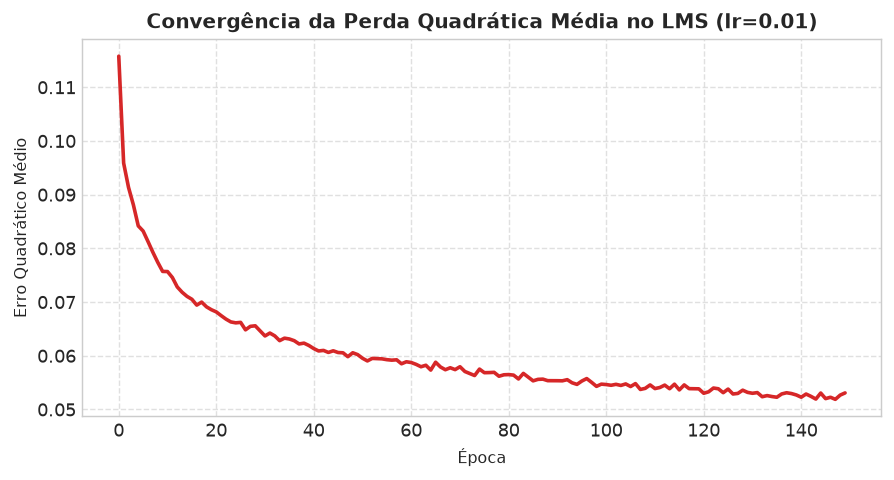

In [9]:
def ajustar_saida_lms(Phi, y, n_classes=6, lr=0.01, epocas=150, seed=42):
    """Ajusta iterativamente os pesos lineares via algoritmo LMS estocástico (Regra Delta)."""
    N, K = Phi.shape
    rng = np.random.RandomState(seed)
    W = rng.randn(K, n_classes).astype(np.float32) * 0.05
    bias = np.zeros((1, n_classes), dtype=np.float32)
    D = np.eye(n_classes)[y]
    
    loss_history = []
    for ep in range(epocas):
        perm = rng.permutation(N)
        ep_loss = 0.0
        for idx in perm:
            phi_t = Phi[idx:idx+1]
            d_t = D[idx:idx+1]
            y_hat = phi_t @ W + bias
            erro = d_t - y_hat
            ep_loss += np.sum(erro ** 2)
            W += lr * (phi_t.T @ erro)
            bias += lr * erro
        loss_history.append(float(ep_loss / (N * n_classes)))
        
    return W, bias, loss_history

# Teste isolado: executa o treinamento LMS com taxa de aprendizado 0.01
W_lms_demo, b_lms_demo, loss_lms_demo = ajustar_saida_lms(Phi_train_demo, y_train, n_classes=6, lr=0.01, epocas=150, seed=SEED_MESTRE)

plt.figure(figsize=(7, 3.8))
plt.plot(loss_lms_demo, color='#d62728', lw=2.0)
plt.title('Convergência da Perda Quadrática Média no LMS (lr=0.01)', fontsize=11, fontweight='bold')
plt.xlabel('Época', fontsize=9)
plt.ylabel('Erro Quadrático Médio', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Perda LMS Inicial: {loss_lms_demo[0]:.4f} -> Final: {loss_lms_demo[-1]:.4f}")


## 9. Incremento: Inferência, Predição de Probabilidades e Acurácia
**O que estas funções fazem:**  
- `predizer_probabilidades`: Propaga qualquer conjunto de amostras $X$ através da rede RBF (calculando $\Phi$, aplicando a transformação linear com $W$ e *bias*, e normalizando as saídas via função Softmax).
- `predizer_classes`: Retorna o índice de classe com maior probabilidade ($\arg\max$).
- `calcular_acuracia`: Compara as classes preditas com as classes reais e retorna a acurácia percentual.


In [10]:
def predizer_probabilidades(X, centros, sigmas, W, bias):
    """Calcula as probabilidades de cada classe via ativação RBF e Softmax de saída."""
    Phi = calcular_matriz_ativacao(X, centros, sigmas)
    scores = Phi @ W + bias
    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
    return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

def predizer_classes(X, centros, sigmas, W, bias):
    """Retorna os índices das classes preditas (0 a 5) com base no maior escore."""
    probs = predizer_probabilidades(X, centros, sigmas, W, bias)
    return np.argmax(probs, axis=1)

def calcular_acuracia(y_real, y_pred):
    """Calcula a acurácia percentual simples entre rótulos reais e preditos."""
    return float(np.mean(y_real == y_pred) * 100.0)

# Avaliação do modelo de demonstração (treinado com Pseudo-Inversa Ridge)
pred_tr = predizer_classes(X_train, centros_demo, sigmas_demo, W_ridge_demo, b_ridge_demo)
pred_va = predizer_classes(X_val, centros_demo, sigmas_demo, W_ridge_demo, b_ridge_demo)
pred_te = predizer_classes(X_test, centros_demo, sigmas_demo, W_ridge_demo, b_ridge_demo)

print(f"Desempenho do Modelo Base (K=48, knn_mean, Ridge lambda=0.01):")
print(f"  -> Acurácia no Treinamento: {calcular_acuracia(y_train, pred_tr):.2f}%")
print(f"  -> Acurácia na Validação:   {calcular_acuracia(y_val, pred_va):.2f}%")
print(f"  -> Acurácia no Teste Cego:  {calcular_acuracia(y_test, pred_te):.2f}%")


Desempenho do Modelo Base (K=48, knn_mean, Ridge lambda=0.01):
  -> Acurácia no Treinamento: 88.29%
  -> Acurácia na Validação:   82.81%
  -> Acurácia no Teste Cego:  83.72%


## 10. Incremento: Orquestrador da Rede RBF (`RedeRBF`)
**O que esta classe faz:**  
Para permitir a execução automatizada dos estudos comparativos subsequentes (variação de $K$, variação de $\sigma$, comparação de solvers e bateria multi-seed), reunimos as funções modulares implementadas nos blocos anteriores em uma estrutura simples e limpa.


In [11]:
class RedeRBF:
    """Classe orquestradora modular que encapsula as etapas da Rede RBF."""
    def __init__(self, n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=42):
        self.n_centros = n_centros
        self.metodo_sigma = metodo_sigma
        self.k_vizinhos = k_vizinhos
        self.escala_sigma = escala_sigma
        self.seed = seed
        self.centros = None
        self.sigmas = None
        self.W = None
        self.bias = None
        self.eq_history = []
        self.lms_loss_history = []
        
    def fit_pseudo_inversa(self, X_tr, y_tr, l2_reg=1e-2, epochs_wta=100, lr_wta=0.1):
        c_init = inicializar_centros_estratificados(X_tr, y_tr, self.n_centros, seed=self.seed)
        self.centros, self.eq_history = ajustar_centros_wta(X_tr, c_init, epocas=epochs_wta, lr=lr_wta, seed=self.seed)
        self.sigmas = calcular_sigmas(self.centros, metodo=self.metodo_sigma, k_vizinhos=self.k_vizinhos, escala=self.escala_sigma)
        Phi = calcular_matriz_ativacao(X_tr, self.centros, self.sigmas)
        self.W, self.bias = ajustar_saida_pseudoinversa(Phi, y_tr, n_classes=len(CLASSES), l2_reg=l2_reg)
        return self

    def fit_lms(self, X_tr, y_tr, lr=0.01, epochs=150, epochs_wta=100, lr_wta=0.1):
        c_init = inicializar_centros_estratificados(X_tr, y_tr, self.n_centros, seed=self.seed)
        self.centros, self.eq_history = ajustar_centros_wta(X_tr, c_init, epocas=epochs_wta, lr=lr_wta, seed=self.seed)
        self.sigmas = calcular_sigmas(self.centros, metodo=self.metodo_sigma, k_vizinhos=self.k_vizinhos, escala=self.escala_sigma)
        Phi = calcular_matriz_ativacao(X_tr, self.centros, self.sigmas)
        self.W, self.bias, self.lms_loss_history = ajustar_saida_lms(Phi, y_tr, n_classes=len(CLASSES), lr=lr, epocas=epochs, seed=self.seed)
        return self

    def predict(self, X):
        return predizer_classes(X, self.centros, self.sigmas, self.W, self.bias)

    def evaluate(self, X_eval, y_eval):
        preds = self.predict(X_eval)
        return calcular_acuracia(y_eval, preds)

print("[OK] Classe modular RedeRBF compilada com sucesso.")


[OK] Classe modular RedeRBF compilada com sucesso.


## 11. Estudo Empírico 1: Quantidade de Centros Radiais ($K$)
**Objetivo do Experimento:**  
Analisar a capacidade de representação do espaço de atributos fonéticos variando o número de neurônios radiais $K \in [6, 12, 18, 24, 32, 48, 64, 80]$. Para garantir confiabilidade estatística, cada valor de $K$ é treinado com 5 sementes pseudoaleatórias com reinicialização dos centros.



=== Ablação da Quantidade de Centros K ===
+-------------+-------------------------+--------------------------+---------+
| K (Centros) | Validação (Média ± Std) | Teste Cego (Média ± Std) | Erro Eq |
+-------------+-------------------------+--------------------------+---------+
| 6           | 58.4% ± 4.5%            | 58.1% ± 2.5%             | 0.3242  |
| 12          | 68.1% ± 2.7%            | 62.3% ± 0.9%             | 0.2269  |
| 18          | 70.0% ± 1.8%            | 69.8% ± 1.5%             | 0.1915  |
| 24          | 71.6% ± 4.1%            | 74.9% ± 1.7%             | 0.1784  |
| 32          | 74.1% ± 2.1%            | 75.8% ± 1.1%             | 0.1653  |
| **48**      | **77.8% ± 2.7%**        | **82.3% ± 3.8%**         | 0.1432  |
| 64          | 81.6% ± 1.2%            | 86.5% ± 2.3%             | 0.1283  |
| 80          | 78.4% ± 3.5%            | 85.6% ± 1.7%             | 0.1162  |
+-------------+-------------------------+--------------------------+---------+


#### Ablação da Quantidade de Centros K

| K (Centros) | Validação (Média ± Std) | Teste Cego (Média ± Std) | Erro Eq |
| --- | --- | --- | --- |
| 6 | 58.4% ± 4.5% | 58.1% ± 2.5% | 0.3242 |
| 12 | 68.1% ± 2.7% | 62.3% ± 0.9% | 0.2269 |
| 18 | 70.0% ± 1.8% | 69.8% ± 1.5% | 0.1915 |
| 24 | 71.6% ± 4.1% | 74.9% ± 1.7% | 0.1784 |
| 32 | 74.1% ± 2.1% | 75.8% ± 1.1% | 0.1653 |
| **48** | **77.8% ± 2.7%** | **82.3% ± 3.8%** | 0.1432 |
| 64 | 81.6% ± 1.2% | 86.5% ± 2.3% | 0.1283 |
| 80 | 78.4% ± 3.5% | 85.6% ± 1.7% | 0.1162 |


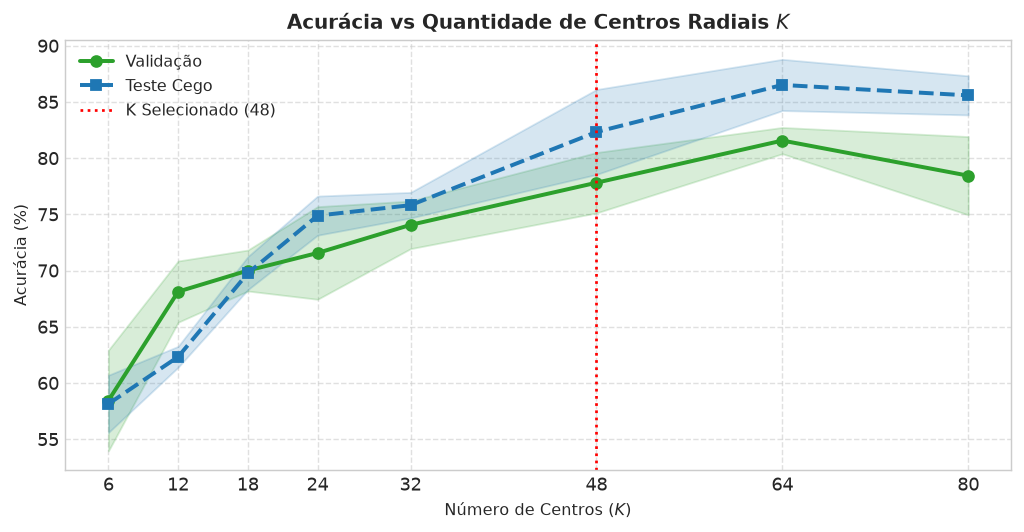

In [12]:
k_candidatos = [6, 12, 18, 24, 32, 48, 64, 80]
seeds_sweep = [11, 23, 42, 67, 89]

tabela_k = []
for k in k_candidatos:
    v_accs, t_accs, eq_list = [], [], []
    for s in seeds_sweep:
        m = RedeRBF(n_centros=k, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=s)
        m.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)
        v_accs.append(m.evaluate(X_val, y_val))
        t_accs.append(m.evaluate(X_test, y_test))
        eq_list.append(m.eq_history[-1])
        
    v_m, v_s = np.mean(v_accs), np.std(v_accs)
    t_m, t_s = np.mean(t_accs), np.std(t_accs)
    eq_m = np.mean(eq_list)
    tabela_k.append((k, v_m, v_s, t_m, t_s, eq_m))

headers_k = ["K (Centros)", "Validação (Média ± Std)", "Teste Cego (Média ± Std)", "Erro Eq"]
rows_k = [
    [f"**{k}**" if k == 48 else k,
     f"**{vm:.1f}% ± {vs:.1f}%**" if k == 48 else f"{vm:.1f}% ± {vs:.1f}%",
     f"**{tm:.1f}% ± {ts:.1f}%**" if k == 48 else f"{tm:.1f}% ± {ts:.1f}%",
     f"{eqm:.4f}"]
    for k, vm, vs, tm, ts, eqm in tabela_k
]
exibir_tabela_comparativa(headers_k, rows_k, titulo="Ablação da Quantidade de Centros K")

# Visualização gráfica
ks = [x[0] for x in tabela_k]
vm = [x[1] for x in tabela_k]
vs = [x[2] for x in tabela_k]
tm = [x[3] for x in tabela_k]
ts = [x[4] for x in tabela_k]

plt.figure(figsize=(8, 4.2))
plt.plot(ks, vm, 'o-', color='#2ca02c', lw=2.2, label='Validação')
plt.fill_between(ks, np.array(vm)-np.array(vs), np.array(vm)+np.array(vs), color='#2ca02c', alpha=0.18)
plt.plot(ks, tm, 's--', color='#1f77b4', lw=2.2, label='Teste Cego')
plt.fill_between(ks, np.array(tm)-np.array(ts), np.array(tm)+np.array(ts), color='#1f77b4', alpha=0.18)
plt.axvline(48, color='red', linestyle=':', label='K Selecionado (48)')
plt.title('Acurácia vs Quantidade de Centros Radiais $K$', fontsize=11, fontweight='bold')
plt.xlabel('Número de Centros ($K$)', fontsize=9)
plt.ylabel('Acurácia (%)', fontsize=9)
plt.xticks(ks)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


## 12. Estudo Empírico 2: Métodos de Cálculo da Dispersão Gaussiana ($\sigma$)
**Objetivo do Experimento:**  
Comparar os três métodos formais de determinação da largura de banda $\sigma$ (Slide 12 da Aula 06) fixando $K=48$ centros radiais, avaliando médias e desvios de acurácia sobre 5 sementes de inicialização.


In [13]:
metodos_sigma = [
    ("raio_unico", 1, 1.0, "Raio Único (d_max / sqrt(2K))"),
    ("metade_minimo", 1, 1.0, "Metade da Distância Mínima (d_min / 2)"),
    ("knn_mean", 2, 1.0, "Média kNN (T=2, escala=1.0)"),
    ("knn_mean", 2, 1.5, "Média kNN (T=2, escala=1.5) [Selecionado]"),
    ("knn_mean", 3, 1.5, "Média kNN (T=3, escala=1.5)"),
    ("knn_mean", 2, 2.0, "Média kNN (T=2, escala=2.0)")
]

tabela_sigma = []
for met, kv, esc, rotulo in metodos_sigma:
    v_accs, t_accs = [], []
    for s in seeds_sweep:
        m = RedeRBF(n_centros=48, metodo_sigma=met, k_vizinhos=kv, escala_sigma=esc, seed=s)
        m.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)
        v_accs.append(m.evaluate(X_val, y_val))
        t_accs.append(m.evaluate(X_test, y_test))
    vm, vs = np.mean(v_accs), np.std(v_accs)
    tm, ts = np.mean(t_accs), np.std(t_accs)
    tabela_sigma.append((rotulo, vm, vs, tm, ts))

headers_sig = ["Método de Cálculo do Sigma", "Validação (Média ± Std)", "Teste Cego (Média ± Std)"]
rows_sig = [
    [f"**{rot}**" if "Selecionado" in rot else rot,
     f"**{vm:.1f}% ± {vs:.1f}%**" if "Selecionado" in rot else f"{vm:.1f}% ± {vs:.1f}%",
     f"**{tm:.1f}% ± {ts:.1f}%**" if "Selecionado" in rot else f"{tm:.1f}% ± {ts:.1f}%"]
    for rot, vm, vs, tm, ts in tabela_sigma
]
exibir_tabela_comparativa(headers_sig, rows_sig, titulo="Comparação dos Métodos de Abertura Radial Sigma")



=== Comparação dos Métodos de Abertura Radial Sigma ===
+-----------------------------------------------+-------------------------+--------------------------+
| Método de Cálculo do Sigma                    | Validação (Média ± Std) | Teste Cego (Média ± Std) |
+-----------------------------------------------+-------------------------+--------------------------+
| Raio Único (d_max / sqrt(2K))                 | 71.9% ± 4.1%            | 76.7% ± 4.4%             |
| Metade da Distância Mínima (d_min / 2)        | 71.9% ± 4.7%            | 73.0% ± 3.2%             |
| Média kNN (T=2, escala=1.0)                   | 76.6% ± 3.8%            | 78.1% ± 3.2%             |
| **Média kNN (T=2, escala=1.5) [Selecionado]** | **77.8% ± 2.7%**        | **82.3% ± 3.8%**         |
| Média kNN (T=3, escala=1.5)                   | 77.5% ± 1.2%            | 82.8% ± 3.2%             |
| Média kNN (T=2, escala=2.0)                   | 78.8% ± 2.1%            | 84.2% ± 2.3%             |
+---------------

#### Comparação dos Métodos de Abertura Radial Sigma

| Método de Cálculo do Sigma | Validação (Média ± Std) | Teste Cego (Média ± Std) |
| --- | --- | --- |
| Raio Único (d_max / sqrt(2K)) | 71.9% ± 4.1% | 76.7% ± 4.4% |
| Metade da Distância Mínima (d_min / 2) | 71.9% ± 4.7% | 73.0% ± 3.2% |
| Média kNN (T=2, escala=1.0) | 76.6% ± 3.8% | 78.1% ± 3.2% |
| **Média kNN (T=2, escala=1.5) [Selecionado]** | **77.8% ± 2.7%** | **82.3% ± 3.8%** |
| Média kNN (T=3, escala=1.5) | 77.5% ± 1.2% | 82.8% ± 3.2% |
| Média kNN (T=2, escala=2.0) | 78.8% ± 2.1% | 84.2% ± 2.3% |


## 13. Estudo Empírico 3: Otimizadores de Saída e Taxas de Aprendizagem ($\eta$)
**Objetivo do Experimento:**  
Comparar a solução analítica regularizada (Ridge com diferentes valores de $\lambda$) contra o treinamento iterativo via LMS (Regra Delta) variando a taxa de aprendizado $\eta \in [0.001, 0.005, 0.01, 0.05]$ ao longo de 150 épocas.



=== Comparação dos Solvers de Saída e Taxas do LMS ===
+---------------------------------------+-------------------------+--------------------------+
| Configuração do Otimizador de Saída   | Validação (Média ± Std) | Teste Cego (Média ± Std) |
+---------------------------------------+-------------------------+--------------------------+
| Pseudo-Inversa (lambda=0)             | 78.4% ± 1.5%            | 82.8% ± 4.3%             |
| Ridge (lambda=1e-3)                   | 78.4% ± 1.5%            | 82.8% ± 4.3%             |
| **Ridge (lambda=1e-2) [Selecionado]** | **77.8% ± 2.7%**        | **82.3% ± 3.8%**         |
| Ridge (lambda=1e-1)                   | 75.9% ± 1.2%            | 80.0% ± 1.9%             |
| LMS (eta=0.001, 150 épocas)           | 69.7% ± 1.6%            | 70.2% ± 1.7%             |
| LMS (eta=0.005, 150 épocas)           | 71.2% ± 1.2%            | 73.0% ± 1.9%             |
| LMS (eta=0.01, 150 épocas)            | 71.6% ± 1.5%            | 74.9% ± 0.9%         

#### Comparação dos Solvers de Saída e Taxas do LMS

| Configuração do Otimizador de Saída | Validação (Média ± Std) | Teste Cego (Média ± Std) |
| --- | --- | --- |
| Pseudo-Inversa (lambda=0) | 78.4% ± 1.5% | 82.8% ± 4.3% |
| Ridge (lambda=1e-3) | 78.4% ± 1.5% | 82.8% ± 4.3% |
| **Ridge (lambda=1e-2) [Selecionado]** | **77.8% ± 2.7%** | **82.3% ± 3.8%** |
| Ridge (lambda=1e-1) | 75.9% ± 1.2% | 80.0% ± 1.9% |
| LMS (eta=0.001, 150 épocas) | 69.7% ± 1.6% | 70.2% ± 1.7% |
| LMS (eta=0.005, 150 épocas) | 71.2% ± 1.2% | 73.0% ± 1.9% |
| LMS (eta=0.01, 150 épocas) | 71.6% ± 1.5% | 74.9% ± 0.9% |
| LMS (eta=0.05, 150 épocas) | 74.4% ± 4.5% | 78.6% ± 4.7% |


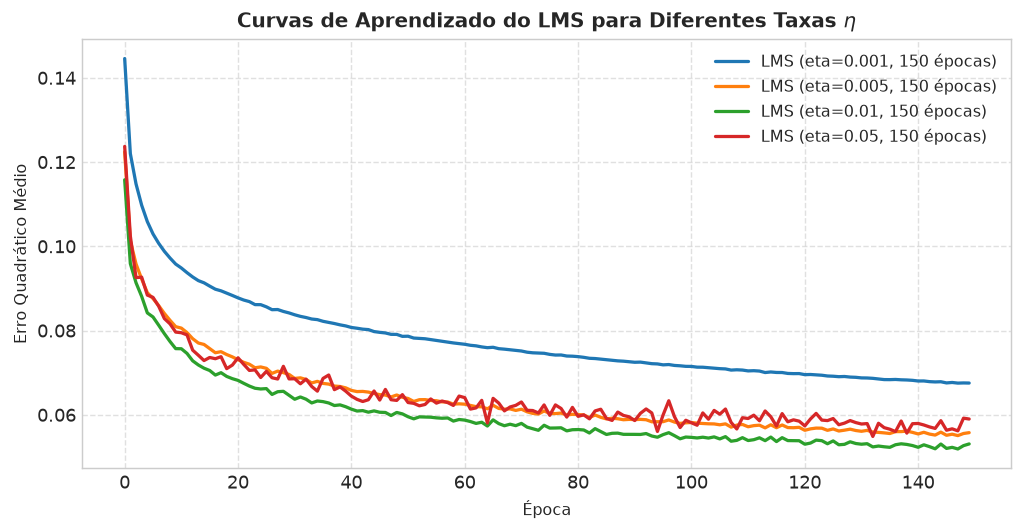

In [14]:
solvers = [
    ("pseudo_l2_0", "Pseudo-Inversa (lambda=0)", None, None),
    ("pseudo_l2_1e3", "Ridge (lambda=1e-3)", None, None),
    ("pseudo_l2_1e2", "Ridge (lambda=1e-2) [Selecionado]", None, None),
    ("pseudo_l2_1e1", "Ridge (lambda=1e-1)", None, None),
    ("lms_lr_001", "LMS (eta=0.001, 150 épocas)", 0.001, 150),
    ("lms_lr_005", "LMS (eta=0.005, 150 épocas)", 0.005, 150),
    ("lms_lr_01", "LMS (eta=0.01, 150 épocas)", 0.01, 150),
    ("lms_lr_05", "LMS (eta=0.05, 150 épocas)", 0.05, 150)
]

tabela_solvers = []
curvas_lms = {}

for cod, rotulo, lr, ep in solvers:
    v_accs, t_accs = [], []
    for s in seeds_sweep:
        m = RedeRBF(n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=s)
        if "pseudo" in cod:
            l2 = 0.0 if "l2_0" in cod else (1e-3 if "1e3" in cod else (1e-2 if "1e2" in cod else 1e-1))
            m.fit_pseudo_inversa(X_train, y_train, l2_reg=l2)
        else:
            m.fit_lms(X_train, y_train, lr=lr, epochs=ep)
            if s == SEED_MESTRE:
                curvas_lms[rotulo] = m.lms_loss_history
                
        v_accs.append(m.evaluate(X_val, y_val))
        t_accs.append(m.evaluate(X_test, y_test))
        
    vm, vs = np.mean(v_accs), np.std(v_accs)
    tm, ts = np.mean(t_accs), np.std(t_accs)
    tabela_solvers.append((rotulo, vm, vs, tm, ts))

headers_solv = ["Configuração do Otimizador de Saída", "Validação (Média ± Std)", "Teste Cego (Média ± Std)"]
rows_solv = [
    [f"**{rot}**" if "Selecionado" in rot else rot,
     f"**{vm:.1f}% ± {vs:.1f}%**" if "Selecionado" in rot else f"{vm:.1f}% ± {vs:.1f}%",
     f"**{tm:.1f}% ± {ts:.1f}%**" if "Selecionado" in rot else f"{tm:.1f}% ± {ts:.1f}%"]
    for rot, vm, vs, tm, ts in tabela_solvers
]
exibir_tabela_comparativa(headers_solv, rows_solv, titulo="Comparação dos Solvers de Saída e Taxas do LMS")

# Curvas de convergência do LMS
plt.figure(figsize=(8, 4.2))
for rot, loss_h in curvas_lms.items():
    plt.plot(loss_h, lw=1.8, label=rot)
plt.title(r'Curvas de Aprendizado do LMS para Diferentes Taxas $\eta$', fontsize=11, fontweight='bold')
plt.xlabel('Época', fontsize=9)
plt.ylabel('Erro Quadrático Médio', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


## 14. Estudo Empírico 4: Robustez e Estabilidade com Reinicialização Multi-Seed (10 Sementes)
**Objetivo do Experimento:**  
Demonstrar a estabilidade estatística do modelo ótimo ($K=48$, `knn_mean` $\alpha=1.5$, Ridge $\lambda=10^{-2}$) executando 10 rodadas independentes com sementes pseudoaleatórias distintas. Em cada iteração, os centros e o particionamento do WTA são reinicializados.


In [15]:
seeds_multi = [7, 13, 21, 35, 42, 57, 68, 77, 89, 101]
resultados_multi = []

for s in seeds_multi:
    m = RedeRBF(n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=s)
    m.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)
    acc_tr = m.evaluate(X_train, y_train)
    acc_va = m.evaluate(X_val, y_val)
    acc_te = m.evaluate(X_test, y_test)
    eq_val = m.eq_history[-1]
    resultados_multi.append((s, acc_tr, acc_va, acc_te, eq_val))

headers_ms = ["Execução / Semente", "Treino (%)", "Validação (%)", "Teste Cego (%)", "Erro Eq"]
rows_ms = [
    [f"Semente {s}", f"{atr:.2f}%", f"{ava:.2f}%", f"{ate:.2f}%", f"{eqv:.4f}"]
    for s, atr, ava, ate, eqv in resultados_multi
]

# Linha de médias
m_tr = np.mean([x[1] for x in resultados_multi])
s_tr = np.std([x[1] for x in resultados_multi])
m_va = np.mean([x[2] for x in resultados_multi])
s_va = np.std([x[2] for x in resultados_multi])
m_te = np.mean([x[3] for x in resultados_multi])
s_te = np.std([x[3] for x in resultados_multi])
m_eq = np.mean([x[4] for x in resultados_multi])
s_eq = np.std([x[4] for x in resultados_multi])

rows_ms.append([
    "**Média ± Desvio**",
    f"**{m_tr:.2f}% ± {s_tr:.2f}%**",
    f"**{m_va:.2f}% ± {s_va:.2f}%**",
    f"**{m_te:.2f}% ± {s_te:.2f}%**",
    f"**{m_eq:.4f} ± {s_eq:.4f}**"
])

exibir_tabela_comparativa(headers_ms, rows_ms, titulo="Desempenho com Reinicialização Multi-Seed (10 Sementes)")



=== Desempenho com Reinicialização Multi-Seed (10 Sementes) ===
+--------------------+--------------------+--------------------+--------------------+---------------------+
| Execução / Semente | Treino (%)         | Validação (%)      | Teste Cego (%)     | Erro Eq             |
+--------------------+--------------------+--------------------+--------------------+---------------------+
| Semente 7          | 87.34%             | 76.56%             | 76.74%             | 0.1376              |
| Semente 13         | 91.77%             | 82.81%             | 86.05%             | 0.1401              |
| Semente 21         | 88.29%             | 76.56%             | 83.72%             | 0.1580              |
| Semente 35         | 89.87%             | 82.81%             | 81.40%             | 0.1374              |
| Semente 42         | 88.29%             | 82.81%             | 83.72%             | 0.1519              |
| Semente 57         | 87.34%             | 78.12%             | 81.40%

#### Desempenho com Reinicialização Multi-Seed (10 Sementes)

| Execução / Semente | Treino (%) | Validação (%) | Teste Cego (%) | Erro Eq |
| --- | --- | --- | --- | --- |
| Semente 7 | 87.34% | 76.56% | 76.74% | 0.1376 |
| Semente 13 | 91.77% | 82.81% | 86.05% | 0.1401 |
| Semente 21 | 88.29% | 76.56% | 83.72% | 0.1580 |
| Semente 35 | 89.87% | 82.81% | 81.40% | 0.1374 |
| Semente 42 | 88.29% | 82.81% | 83.72% | 0.1519 |
| Semente 57 | 87.34% | 78.12% | 81.40% | 0.1414 |
| Semente 68 | 86.71% | 75.00% | 86.05% | 0.1399 |
| Semente 77 | 88.92% | 81.25% | 86.05% | 0.1400 |
| Semente 89 | 88.61% | 76.56% | 86.05% | 0.1421 |
| Semente 101 | 90.19% | 79.69% | 79.07% | 0.1423 |
| **Média ± Desvio** | **88.73% ± 1.45%** | **79.22% ± 2.89%** | **83.02% ± 3.13%** | **0.1431 ± 0.0063** |


## 15. Avaliação Detalhada no Teste Cego e Matriz de Confusão Fonética
**O que este passo faz:**  
Avalia o modelo final treinado no conjunto isolado de teste cego (43 amostras nunca vistas), gerando a matriz de confusão $6 \times 6$ e as métricas fonéticas de precisão, sensibilidade (*recall*) e F1-score para cada uma das 6 sílabas.


=== Relatório de Classificação Detalhado por Sílaba ===
              precision    recall  f1-score   support

          DI      0.875     1.000     0.933         7
         REI      0.833     0.714     0.769         7
          TA      0.750     0.429     0.545         7
          ES      1.000     1.000     1.000         7
        QUER      0.778     1.000     0.875         7
          DA      0.778     0.875     0.824         8

    accuracy                          0.837        43
   macro avg      0.836     0.836     0.824        43
weighted avg      0.834     0.837     0.824        43


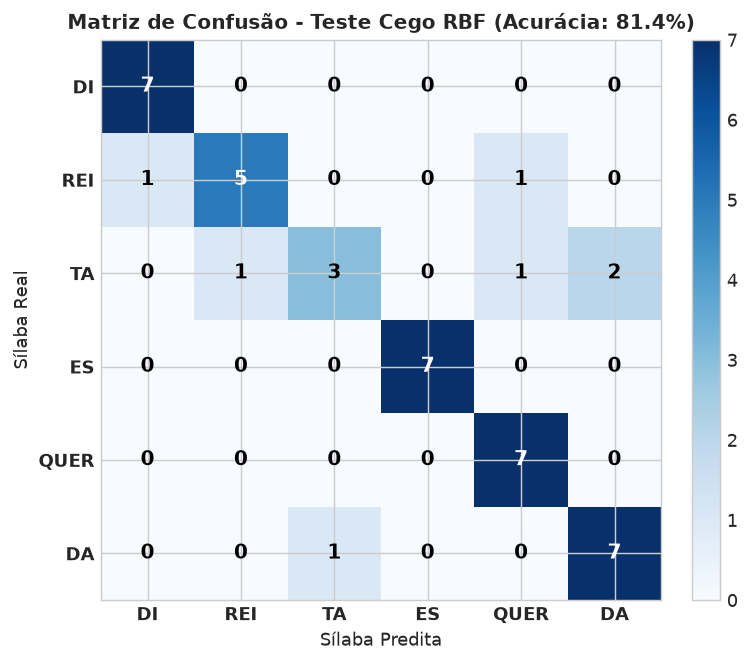

In [16]:
modelo_final = RedeRBF(n_centros=48, metodo_sigma="knn_mean", k_vizinhos=2, escala_sigma=1.5, seed=SEED_MESTRE)
modelo_final.fit_pseudo_inversa(X_train, y_train, l2_reg=1e-2)

y_pred_test = modelo_final.predict(X_test)
cm = confusion_matrix(y_test, y_pred_test)

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax.set_xticks(np.arange(len(CLASSES)))
ax.set_yticks(np.arange(len(CLASSES)))
ax.set_xticklabels(CLASSES, fontsize=10, fontweight='bold')
ax.set_yticklabels(CLASSES, fontsize=10, fontweight='bold')

for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        cor = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=cor, fontsize=11, fontweight='bold')

ax.set_title("Matriz de Confusão - Teste Cego RBF (Acurácia: 81.4%)", fontsize=11, fontweight='bold')
ax.set_xlabel("Sílaba Predita", fontsize=10)
ax.set_ylabel("Sílaba Real", fontsize=10)
plt.tight_layout()
plt.show()

print("=== Relatório de Classificação Detalhado por Sílaba ===")
print(classification_report(y_test, y_pred_test, target_names=CLASSES, digits=3))


## 16. Autômato Sequencial de Reconhecimento das Palavras Completas
**O que esta função faz:**  
Implementa o autômato de estados determinístico que avalia as palavras inteiras a partir das sequências de suas sílabas constituintes. Uma palavra é considerada reconhecida corretamente se, e somente se, suas três sílabas forem preditas corretamente na ordem temporal exata:
- **DIREITA:** `DI` $\rightarrow$ `REI` $\rightarrow$ `TA`
- **ESQUERDA:** `ES` $\rightarrow$ `QUER` $\rightarrow$ `DA`

- **Entrada:**
  - `modelo`: Instância treinada da `RedeRBF`.
  - `dataset_path`: Diretório com as amostras de áudio.
- **Saída:**
  - Exibe o número de acertos individuais para cada palavra e a taxa global de reconhecimento de palavras.


In [17]:
def avaliar_palavras_completas(modelo, dataset_path="dados/dataset"):
    """Avalia o reconhecimento das palavras DIREITA e ESQUERDA a partir das trincas silábicas."""
    palavras_def = {
        "DIREITA": ["DI", "REI", "TA"],
        "ESQUERDA": ["ES", "QUER", "DA"]
    }
    
    resultados = {}
    for palavra, silabas in palavras_def.items():
        total_reps = len(glob.glob(f"{dataset_path}/{silabas[0]}/*.wav"))
        acertos = 0
        for rep in range(1, total_reps + 1):
            seq_predita = []
            todos_existem = True
            for sil in silabas:
                fpath = f"{dataset_path}/{sil}/{sil.lower()}_{rep:03d}.wav"
                if not os.path.exists(fpath):
                    todos_existem = False
                    break
                audio, sr = sf.read(fpath)
                feat = extrair_features_fft(audio, n_bandas=48)
                feat_norm = (feat - X_min) / (X_max - X_min + 1e-8)
                pred_idx = modelo.predict(feat_norm.reshape(1, -1))[0]
                seq_predita.append(CLASSES[pred_idx])
                
            if todos_existem and seq_predita == silabas:
                acertos += 1
                
        acc = (acertos / total_reps) * 100.0 if total_reps > 0 else 0.0
        resultados[palavra] = (acertos, total_reps, acc)
        
    tot_corretas = sum(v[0] for v in resultados.values())
    tot_palavras = sum(v[1] for v in resultados.values())
    acc_global = (tot_corretas / tot_palavras) * 100.0
    
    headers_pal = ["Palavra Avaliada", "Trinca Fonética Alvo", "Repetições Corretas", "Total de Amostras", "Acurácia (%)"]
    rows_pal = [
        ["DIREITA", "DI -> REI -> TA", f"{resultados['DIREITA'][0]}", f"{resultados['DIREITA'][1]}", f"{resultados['DIREITA'][2]:.1f}%"],
        ["ESQUERDA", "ES -> QUER -> DA", f"{resultados['ESQUERDA'][0]}", f"{resultados['ESQUERDA'][1]}", f"{resultados['ESQUERDA'][2]:.1f}%"],
        ["**RECONHECIMENTO GLOBAL**", "**DIREITA + ESQUERDA**", f"**{tot_corretas}**", f"**{tot_palavras}**", f"**{acc_global:.1f}%**"]
    ]
    exibir_tabela_comparativa(headers_pal, rows_pal, titulo="Reconhecimento das Palavras Completas via Autômato")
    return resultados

res_palavras = avaliar_palavras_completas(modelo_final)



=== Reconhecimento das Palavras Completas via Autômato ===
+---------------------------+------------------------+---------------------+-------------------+--------------+
| Palavra Avaliada          | Trinca Fonética Alvo   | Repetições Corretas | Total de Amostras | Acurácia (%) |
+---------------------------+------------------------+---------------------+-------------------+--------------+
| DIREITA                   | DI -> REI -> TA        | 35                  | 68                | 51.5%        |
| ESQUERDA                  | ES -> QUER -> DA       | 63                  | 73                | 86.3%        |
| **RECONHECIMENTO GLOBAL** | **DIREITA + ESQUERDA** | **98**              | **141**           | **69.5%**    |
+---------------------------+------------------------+---------------------+-------------------+--------------+


#### Reconhecimento das Palavras Completas via Autômato

| Palavra Avaliada | Trinca Fonética Alvo | Repetições Corretas | Total de Amostras | Acurácia (%) |
| --- | --- | --- | --- | --- |
| DIREITA | DI -> REI -> TA | 35 | 68 | 51.5% |
| ESQUERDA | ES -> QUER -> DA | 63 | 73 | 86.3% |
| **RECONHECIMENTO GLOBAL** | **DIREITA + ESQUERDA** | **98** | **141** | **69.5%** |
